# Chương 3 — Linear Neural Networks for Regression

**Người làm: Lê Sơn Trường.** Đối chiếu PDF D2L 1.0.3 trang 132–164.


Nguồn: [D2L chương 3](https://d2l.ai/chapter_linear-regression/index.html). Lời giải giữ số câu để đối chiếu PDF. Chạy **Run All**; mặc định đọc cache kết quả thật. Đổi `RECOMPUTE=True` để học lại bằng nguồn `.py` đi kèm.

In [1]:
from pathlib import Path
import sys

cwd = Path.cwd().resolve()
paths = [cwd, cwd / "bai_lam_Le_Son_Truong", cwd / "Buoi2" / "bai_lam_Le_Son_Truong",
         *[p / "Buoi2" / "bai_lam_Le_Son_Truong" for p in cwd.parents]]
BASE = next((p for p in paths if (p / "experiments.py").is_file()), None)
if BASE is None:
    raise FileNotFoundError("Mở notebook trong repository DeepL hoặc thư mục bài làm Buoi2.")
sys.path.insert(0, str(BASE))
from experiments import run_section, render_result

# False: đọc lại kết quả thật đã lưu. True: chạy lại các thí nghiệm (tốn thời gian).
RECOMPUTE = False
if RECOMPUTE:
    from data import prepare
    prepare()
print("Người làm: Lê Sơn Trường | D2L 1.0.3 | CPU, seed 42")


Người làm: Lê Sơn Trường | D2L 1.0.3 | CPU, seed 42


## 3.1 — Linear Regression (8 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 132 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. Assume that we have some data𝑥1,...,𝑥 𝑛∈ R. Our goal is to find a constant𝑏 such
that ˝𝑖(𝑥𝑖−𝑏)2 is minimized.
1. Find an analytic solution for the optimal value of𝑏.
2. How does this problem and its solution relate to the normal distribution?
3. What if we change the loss from˝𝑖(𝑥𝑖−𝑏)2 to ˝𝑖|𝑥𝑖−𝑏|? Can you find the optimal
solution for𝑏?
2. Prove that the affine functions that can be expressed byx⊤w+𝑏 are equivalent to linear
functions on(x, 1).
3. Assume that you want to find quadratic functions ofx, i.e., 𝑓(x) = 𝑏+ ˝𝑖𝑤𝑖𝑥𝑖+˝
𝑗≤𝑖𝑤𝑖𝑗𝑥𝑖𝑥𝑗. How would you formulate this in a deep network?
4. Recall that one of the conditions for the linear regression problem to be solvable was
that the design matrixX⊤X has full rank.
1. What happens if this is not the case?
2. How could you fix it? What happens if you add a small amount of coordinate-wise
independent Gaussian noise to all entries ofX?
3. What is the expected value of the design matrixX⊤X in this case?
4. What happens with stochastic gradient descent whenX⊤X does not have full rank?
5. Assume that the noise model governing the additive noise𝜖 is the exponential distribu-
tion. That is,𝑝(𝜖) = 12 exp(−|𝜖|).
1. Write out the negative log-likelihood of the data under the model− log𝑃(y| X).
2. Can you find a closed form solution?
3. Suggest a minibatch stochastic gradient descent algorithm to solve this problem.
What could possibly go wrong (hint: what happens near the stationary point as we
keep on updating the parameters)? Can you fix this?
6. Assume that we want to design a neural network with two layers by composing two
linear layers. That is, the output of the first layer becomes the input of the second layer.
Why would such a naive composition not work?
7. What happens if you want to use regression for realistic price estimation of houses or
stock prices?
93 Object-Oriented Design for Implementation
68
69
70
1. Show that the additive Gaussian noise assumption is not appropriate. Hint: can we
have negative prices? What about fluctuations?
2. Whywouldregressiontothelogarithmofthepricebemuchbetter,i.e., 𝑦 = logprice?
3. Whatdoyouneedtoworryaboutwhendealingwithpennystock,i.e.,stockwithvery
low prices? Hint: can you trade at all possible prices? Why is this a bigger problem
for cheap stock? For more information review the celebrated Black–Scholes model
for option pricing (Black and Scholes, 1973).
8. Suppose we want to use regression to estimate thenumber of apples sold in a grocery
store.
1. What are the problems with a Gaussian additive noise model? Hint: you are selling
apples, not oil.
2. The Poisson distribution68 captures distributions over counts. It is given by𝑝(𝑘|
𝜆) = 𝜆𝑘𝑒−𝜆/𝑘!. Here𝜆 is the rate function and𝑘 is the number of events you see.
Prove that𝜆 is the expected value of counts𝑘.
3. Design a loss function associated with the Poisson distribution.
4. Design a loss function for estimatinglog𝜆 instead.
</pre>
</details>


### Câu 1

1. J(b)=Σ(xᵢ−b)²; J'(b)=2(nb−Σxᵢ)=0 ⇒ **b=mean(x)**;
   J''=2n>0 nên cực tiểu duy nhất khi n>0.
2. Nếu xᵢ IID Gaussian cùng mean b, variance cố định, cực đại likelihood tương
   đương cực tiểu bình phương sai số; mean mẫu là MLE của b.
3. Với Σ|xᵢ−b|, nghiệm là median; n chẵn có thể là cả khoảng giữa hai giá trị giữa.

### Câu 2

Đặt x̃=[x;1], w̃=[w;b] thì x̃ᵀw̃=xᵀw+b. Affine trên x là tuyến tính trên
không gian đặc trưng mở rộng; không có nghĩa nó tuyến tính thuần túy trên x.

### Câu 3

Tạo tầng đặc trưng `[1,x₁,…,x_d,x₁²,x₁x₂,…,x_d²]`, rồi tầng tuyến tính cho
đầu ra. Đây là mô hình tuyến tính theo tham số nhưng phi tuyến theo x.
Chỉ ghép các Linear không có tương tác/activation thì không tạo được xᵢxⱼ chính xác.

### Câu 4

1. XᵀX thiếu hạng: nghịch đảo không tồn tại; nghiệm bình phương tối thiểu vẫn có
   nhưng hệ số có thể không duy nhất.
2. Dùng pseudoinverse/SVD, loại cột phụ thuộc hoặc ridge. Nhiễu Gaussian độc lập
   có thể phá phụ thuộc chính xác khi n≥d; nếu n<d thì hạng vẫn≤n nên không thể đầy hạng cột.
3. Với X cố định và Eᵢⱼ IID mean 0, variance σ²:
   E[(X+E)ᵀ(X+E)]=XᵀX+nσ²I. Đó là kỳ vọng, không bảo đảm một mẫu có điều kiện tốt.
4. SGD có thể hội tụ tới một nghiệm tùy khởi tạo, LR và thành phần null space;
   dự đoán trên train có thể duy nhất dù hệ số không duy nhất. Với zero init và điều
   kiện thích hợp, gradient descent tuyến tính có thể chọn nghiệm norm nhỏ nhất.

### Câu 5

Mật độ (1/2)exp(−|ε|) trong đề thực ra là **Laplace hai phía**, không phải
exponential một phía. NLL = n log 2 + Σ|yᵢ−xᵢᵀw−b|. Intercept-only có
nghiệm median; hồi quy tổng quát không có công thức nghịch đảo đơn giản, có thể
giải bằng linear programming hoặc subgradient SGD. Một minibatch dùng gradient
`sign(yhat−y)*x`, trung bình theo batch. Gần nghiệm, gradient có thể đổi dấu và
dao động; giảm LR, averaging hoặc Huber loss giúp ổn định.

### Câu 6

Hai tầng affine ghép nhau vẫn affine:
`W₂(W₁x+b₁)+b₂=(W₂W₁)x+(W₂b₁+b₂)`. Không tăng khả năng biểu diễn phi tuyến;
nếu tầng giữa hẹp còn hạn chế hạng của phép biến đổi.

### Câu 7

1. Gaussian cộng có thể cho giá âm và variance tuyệt đối cố định, không phù hợp
   khi sai số thường mang tính tỷ lệ.
2. Học log(price) với giá dương giúp mô hình hóa biến động tương đối; exp đầu ra
   cho giá dương. Exp của dự đoán mean log không mặc nhiên là mean giá gốc
   (cần xét bias khi back-transform).
3. Giá giao dịch có bước giá rời rạc; cùng một tick là tỷ lệ thay đổi lớn hơn
   ở giá rất nhỏ. Đây là phân tích mô hình toán học theo đề, không phải tư vấn đầu tư.

### Câu 8

1. Số táo là số nguyên không âm; Gaussian liên tục có thể cho số âm/phân số.
2. Với K~Poisson(λ): E[K]=Σk·λᵏe⁻λ/k! = λe⁻λΣ[j≥0]λʲ/j! = λ.
3. NLL mỗi mẫu là `λ−k log λ+log(k!)`, λ>0; phần factorial không phụ thuộc tham số.
4. Đặt η=log λ thì loss=`exp η−kη+log(k!)`, gradient theo η=`exp η−k`.

In [2]:
result = run_section("3.1", recompute=RECOMPUTE)
render_result(result)

Squared-loss minimizer mean=26.5, absolute-loss minimizers interval [2,3].


**analytic_regression**

,parameter,estimate
0,w1,2.000121
1,w2,-3.400014
2,bias,4.200210


## 3.2 — Object-Oriented Design (2 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 138 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. Locate full implementations of the above classes that are saved in theD2L library73
. We strongly recommend that you look at the implementation in detail once you have
gained some more familiarity with deep learning modeling.
99 Synthetic Regression Data
74
2. Removethe save_hyperparametersstatementinthe Bclass. Canyoustillprint self.a
and self.b? Optional: if you have dived into the full implementation of theHyperPa-
rameters class, can you explain why?
</pre>
</details>


### Câu 1

Mã đầy đủ của HyperParameters, Module, DataModule, Trainer có ở
https://d2l.ai/_modules/d2l/torch.html và nguồn `d2l/torch.py` của D2L 1.0.3.
Bài làm lưu bản nguồn tham khảo tại `source_reference/d2l_torch.py`.
HyperParameters giữ cấu hình; Module mô tả mô hình/loss/optimizer;
DataModule cung cấp loader; Trainer điều phối forward/backward/update/validation.
Các phương thức được thêm dần bằng `add_to_class`, nên bản trong một đoạn sách
có thể chưa đầy đủ như thư viện.

### Câu 2

Nếu `B.__init__` chỉ nhận a,b mà không gán `self.a`, `self.b`, bỏ
`save_hyperparameters()` thì không còn hai thuộc tính đó, truy cập sẽ AttributeError.
Hàm tiện ích đọc biến cục bộ của frame gọi rồi gán lên self; tham số hàm không tự
trở thành thuộc tính đối tượng. Nếu superclass hoặc code khác đã gán chúng thì cần
xét riêng; ví dụ tối thiểu trong notebook không có các phép gán ấy.

In [3]:
result = run_section("3.2", recompute=RECOMPUTE)
render_result(result)

Without assigning/saving hyperparameters: hasattr(a)=False; hasattr(b)=False
Full reference classes: https://d2l.ai/_modules/d2l/torch.html#HyperParameters; Module; DataModule; Trainer. See downloaded source_reference/d2l_torch.py.


## 3.3 — Synthetic Regression Data (4 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 142 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. What will happen if the number of examples cannot be divided by the batch size. How
would you change this behavior by specifying a different argument by using the frame-
work’s API?
2. Suppose that we want to generate a huge dataset, where both the size of the parameter
vector w and the number of examplesnum_examples are large.
1. What happens if we cannot hold all data in memory?
2. Howwouldyoushufflethedataifitisheldondisk? Yourtaskistodesignan eﬀicient
algorithm that does not require too many random reads or writes. Hint:pseudoran-
dom permutation generators75 allow you to design a reshuffle without the need to
store the permutation table explicitly (Naor and Reingold, 1999).
3. Implement a data generator that produces new data on the fly, every time the iterator is
called.
4. How would you design a random data generator that generatesthe samedata each time
it is called?
</pre>
</details>


### Câu 1

Nếu N không chia hết B, DataLoader mặc định giữ minibatch cuối nhỏ hơn.
Ví dụ N=101,B=32 → 32,32,32,5; `drop_last=True` → ba batch 32, bỏ 5 mẫu.
Khi tính loss trung bình cả epoch, phải cân theo số mẫu chứ không trung bình đều batch.

### Câu 2

Không đủ RAM: dùng streaming/IterableDataset, memory map hoặc shard trên đĩa.
Shuffle hiệu quả: shuffle thứ tự shard/block, đọc tuần tự từng block và shuffle
trong buffer RAM; hoặc dùng phép hoán vị giả ngẫu nhiên trên chỉ số và gom các
truy cập theo block để giảm seek. Block shuffle chỉ gần tương đương shuffle toàn bộ;
nếu cần hoán vị toàn cục chính xác thì dùng external shuffle nhiều lượt hoặc
khóa ngẫu nhiên + external sort, tốn I/O nhưng không cần giữ toàn bộ bảng hoán vị.

### Câu 3

Notebook định nghĩa IterableDataset Fresh: mỗi lần `__iter__` sinh x mới bằng
`torch.randn`, rồi y=xᵀw+b. Nhãn và đặc trưng được sinh theo từng mẫu, không lưu toàn bộ.

### Câu 4

Trong `__iter__`, tạo generator cục bộ cùng seed cố định rồi truyền vào mọi lần
sinh số. Hai iterator sẽ tạo lại cùng dữ liệu. Khi chạy nhiều worker cần thiết kế
seed/sharding để không vô tình lặp mẫu giữa các worker.

In [4]:
result = run_section("3.3", recompute=RECOMPUTE)
render_result(result)

Fresh equal on two iterations: False; Fixed equal: True
    class Fresh(IterableDataset):
        def __iter__(self):
            for _ in range(3):
                x=torch.randn(2);yield x,2*x[0]-3.4*x[1]+4.2

    class Fixed(IterableDataset):
        def __iter__(self):
            g=torch.Generator().manual_seed(42)
            for _ in range(3):
                x=torch.randn(2,generator=g);yield x,2*x[0]-3.4*x[1]+4.2



**last_batch**

,drop_last,batch_sizes
0,False,"[32, 32, 32, 5]"
1,True,"[32, 32, 32]"


## 3.4 — Linear Regression from Scratch (9 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 147 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. What would happen if we were to initialize the weights to zero. Would the algorithm
still work? What if we initialized the parameters with variance1000 rather than0.01?
2. Assume that you areGeorg Simon Ohm77 trying to come up with a model for resis-
tance that relates voltage and current. Can you use automatic differentiation to learn the
parameters of your model?
3. Can you usePlanck’s Law78 to determine the temperature of an object using spectral
energy density? For reference, the spectral density𝐵 of radiation emanating from a
black body is𝐵(𝜆,𝑇) = 2ℎ𝑐2𝜆5 · (exp ℎ𝑐𝜆𝑘𝑇− 1)−1. Here 𝜆 is the wavelength,𝑇 is the
temperature, 𝑐 is the speed of light,ℎ is Planck’s constant, and𝑘 is the Boltzmann
constant. You measure the energy for different wavelengths𝜆 and you now need to fit
the spectral density curve to Planck’s law.
4. Whataretheproblemsyoumightencounterifyouwantedtocomputethesecondderiva-
tives of the loss? How would you fix them?
5. Why is thereshape method needed in theloss function?
6. Experimentusingdifferentlearningratestofindouthowquicklythelossfunctionvalue
drops. Can you reduce the error by increasing the number of epochs of training?
108 Linear Neural Networks for Regression
79
7. Ifthenumberofexamplescannotbedividedbythebatchsize,whathappensto data_iter
at the end of an epoch?
8. Try implementing a different loss function, such as the absolute value loss(y_hat -
d2l.reshape(y, y_hat.shape)).abs().sum() .
1. Check what happens for regular data.
2. Check whether there is a difference in behavior if you actively perturb some entries,
such as𝑦5 = 10000, ofy.
3. Can you think of a cheap solution for combining the best aspects of squared loss and
absolute value loss? Hint: how can you avoid really large gradient values?
9. Why do we need to reshuffle the dataset? Can you design a case where a maliciously
constructed dataset would break the optimization algorithm otherwise?
</pre>
</details>


### Câu 1

Hồi quy tuyến tính không có các neuron ẩn đồng vai trò nên zero init vẫn học được.
Variance khởi tạo 1000 nghĩa là std=√1000, không phải std=1000: dự đoán/loss
đầu lớn hơn, có thể mất nhiều bước hoặc mất ổn định với LR lớn. Notebook so sánh
zero, std=0.01 (variance=0.0001, cách sinh trong code sách), std=0.1
(variance=0.01 đúng theo chữ “variance” của câu hỏi), và std=√1000 trên cùng dữ liệu.
Không được coi variance và standard deviation là một đại lượng.

### Câu 2

Định luật Ohm V=RI. Tạo tham số R requires_grad; tối thiểu mean(Vhat−V)² bằng
autograd và SGD. Notebook khôi phục R=7 từ dữ liệu giả lập; kết quả đo được in ra,
không phải thí nghiệm điện vật lý.

### Câu 3

Giữ λ và h,c,k đúng đơn vị SI; tham số hóa T=exp θ để T>0. Fit phổ giả lập
Planck ở nhiều bước sóng bằng loss trên log B; tính expm1 để ổn định khi số mũ
nhỏ. Notebook học T từ khởi tạo 3000 K đến gần nhiệt độ thật 4500 K.
Với dữ liệu đo thực, cần thêm nhiễu, hiệu chuẩn và có thể hệ số phát xạ;
không khẳng định một phép fit đơn giản xác định mọi vật thể.

### Câu 4

Backward mặc định không giữ graph của gradient. Dùng `autograd.grad(...,
create_graph=True)` để đạo hàm tiếp. Hessian n×n tốn bộ nhớ và thời gian; HVP,
autograd.functional.hessian, hoặc xấp xỉ bậc hai phù hợp hơn tùy mục tiêu.
ReLU tại điểm gãy không có đạo hàm cổ điển; không coi mọi Hessian là tồn tại trơn.

### Câu 5

yhat shape `(B,1)`, y shape `(B,)` nếu trừ trực tiếp sẽ broadcast thành `(B,B)`.
`y.reshape(yhat.shape)` bảo đảm mỗi dự đoán so đúng một nhãn.

### Câu 6

Notebook vẽ loss với LR 0.003, 0.03, 0.3 trong 10 epoch. LR nhỏ học chậm;
LR lớn có thể nhanh nhưng vượt ngưỡng ổn định thì dao động/phân kỳ.
Thêm epoch có thể giảm lỗi tối ưu, không bảo đảm giảm lỗi validation mãi.
Các giá trị này là khảo sát theo yêu cầu, không đổi baseline 3 epoch, LR=0.03 của sách.

### Câu 7

Iterator giữ batch cuối nhỏ hơn nếu không drop_last. Nếu loss dùng tổng và chia
cho batch_size cố định, batch cuối bị scale sai; dùng trung bình theo số mẫu thực.

### Câu 8

Notebook chạy squared/L1/Huber trên cùng dữ liệu sạch và dữ liệu có y[5]=10000,
so sánh sai số trọng số và bias, không so trực tiếp trị số giữa các loss khác đơn vị.
Squared loss có gradient theo residual nên outlier chi phối; L1 có gradient biên độ
không đổi nhưng khó tối ưu gần 0. Huber bậc hai gần 0, tuyến tính khi residual lớn,
giúp kết hợp tính trơn gần nghiệm và độ bền trước outlier.

### Câu 9

Shuffle làm minibatch đại diện hơn, giảm thiên lệch do thứ tự. Ví dụ x=1,
nhãn gồm một block +1 rồi một block −1; SGD LR lớn có xu hướng chạy theo block
cuối ở mỗi epoch. Không phải mọi dữ liệu không shuffle đều thất bại, nhưng thứ tự
đối nghịch có thể gây dao động hoặc hội tụ chậm; shuffle không thay thế việc chọn LR hợp lý.

Ohm fitted R=7.000000, true R=7
Planck fitted T=4500.000 K, true 4500 K; synthetic noiseless spectrum
Initialization: std=0.01 means variance=0.0001. Literal variance=0.01 in the exercise is tested separately with std=0.1; variance=1000 uses std=sqrt(1000).


**initialization**

,init_std,init_variance,loss,w_error
0,0.000000,0.0000,0.060035,0.263653
1,0.010000,0.0001,0.059940,0.263324
2,0.100000,0.0100,0.059115,0.260457
3,31.622777,1000.0000,3.371111,2.537647


**learning_rates**

,lr,final_loss
0,0.003,2.515327
1,0.030,0.000050
2,0.300,0.000052


**robust_losses**

,outlier,loss,w_error,bias_error
0,False,mse,0.000394,0.000240
1,False,l1,0.017625,0.001875
2,False,huber,0.038848,0.023034
3,True,mse,13.925745,10.175630
4,True,l1,0.021627,0.007498
5,True,huber,0.038209,0.022212


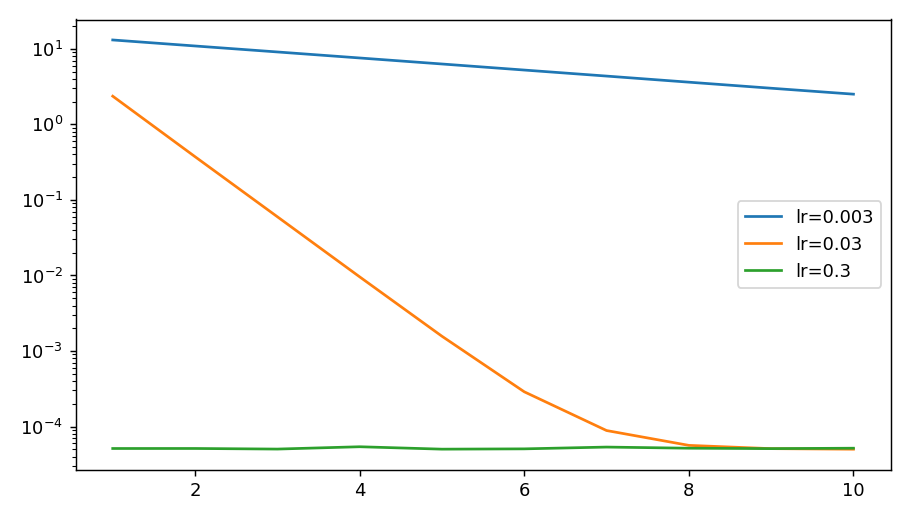

In [5]:
result = run_section("3.4", recompute=RECOMPUTE)
render_result(result)

## 3.5 — Concise Linear Regression (5 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 151 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. How would you need to change the learning rate if you replace the aggregate loss over
the minibatch with an average over the loss on the minibatch?
2. Review the framework documentation to see which loss functions are provided. In par-
ticular, replace the squared loss with Huber’s robust loss function. That is, use the loss
function
𝑙(𝑦,𝑦′) =
{
|𝑦−𝑦′|− 𝜎2 if|𝑦−𝑦′| &gt;𝜎
1
2𝜎(𝑦−𝑦′)2 otherwise (3.5.1)
3. How do you access the gradient of the weights of the model?
112 Linear Neural Networks for Regression
80
4. What is the effect on the solution if you change the learning rate and the number of
epochs? Does it keep on improving?
5. How does the solution change as you vary the amount of data generated?
1. Plot the estimation error forˆw− w and ˆ𝑏−𝑏 as a function of the amount of data.
Hint: increase the amount of data logarithmically rather than linearly, i.e., 5, 10, 20,
50, …, 10,000 rather than 1000, 2000, …, 10,000.
2. Why is the suggestion in the hint appropriate?
</pre>
</details>


### Câu 1

Nếu cập nhật cũ dùng **gradient tổng trực tiếp** với LR η, đổi loss thành mean
thì gradient giảm B lần; muốn cùng bước phải đặt η_mean=Bη_sum.
Nếu code cũ đã chia gradient tổng cho B trong optimizer thì mean loss dùng cùng η,
không chia thêm lần nữa. Phải kiểm tra reduction và bước update cùng nhau.

### Câu 2

Công thức của sách là scaled Huber: `e²/(2σ)` nếu |e|≤σ, và `|e|−σ/2` nếu ngoài.
`torch.nn.HuberLoss(delta=σ)` cho `e²/2` và `σ(|e|−σ/2)`, nên chia cho σ
để khớp sách; `SmoothL1Loss(beta=σ)` cũng khớp. Với σ=1 chúng trùng nhau.
Notebook dùng delta=1 và so sánh trong mục 3.4, đồng thời chạy bản framework ở mục này.

### Câu 3

Sau backward, đọc `model.weight.grad` hoặc `model.net[...].weight.grad`.
Gradient chưa có trước backward, bị reset khi zero_grad, và cộng dồn nếu không reset.

### Câu 4

LR/epoch quyết định mức hội tụ và ổn định. Thêm epoch không cải thiện vô hạn:
có đáy nhiễu, độ chính xác số, và có thể overfitting. Xem đường học của 3.4;
không dùng training loss làm bằng chứng duy nhất về tổng quát hóa.

### Câu 5

Notebook vẽ ‖ŵ−w‖₂ và |b̂−b| theo n=5,10,20,50,…,10000, lấy trung bình
10 seed dữ liệu. Đường chính chạy mô hình framework với **SGD LR=0.03, 3 epoch,
batch32** như ví dụ; có thêm least-squares chính xác làm tham chiếu để tách
tác động thống kê khỏi lỗi chưa hội tụ. Cùng số epoch nhưng n lớn hơn cũng có
nhiều bước SGD hơn. Với mô hình đúng và đủ điều kiện, lỗi thống kê thường giảm cỡ 1/√n,
nhưng từng mẫu có thể không giảm đều. Dải n theo log bao phủ nhiều bậc độ lớn,
giúp quan sát hiệu quả tăng dữ liệu thay vì chỉ một vùng hẹp.

Framework Huber final loss=2.2865465; weight.grad=[[-0.20225602388381958, 0.09151758253574371]]
Sample-size plot includes framework SGD with the book's LR=0.03 and 3 epochs, plus exact least squares as a separate reference. Ten data seeds per size. Larger n also means more SGD updates at fixed epochs.


**data_size**

,n,sgd_w_error_mean,sgd_bias_error_mean,ols_w_error_mean,ols_bias_error_mean
0,5,3.539279,3.882865,0.008354,0.003237
1,10,3.577016,3.815527,0.004990,0.003784
2,20,3.633593,3.816704,0.002415,0.001484
3,50,3.335860,3.528841,0.001223,0.001547
4,100,2.774738,2.954181,0.001334,0.001190
5,200,2.256927,2.291419,0.000856,0.000723
6,500,0.983070,1.007204,0.000558,0.000266
7,1000,0.248826,0.233757,0.000409,0.000321
8,5000,0.000299,0.000122,0.000204,0.000129
9,10000,0.000303,0.000171,0.000109,0.000083


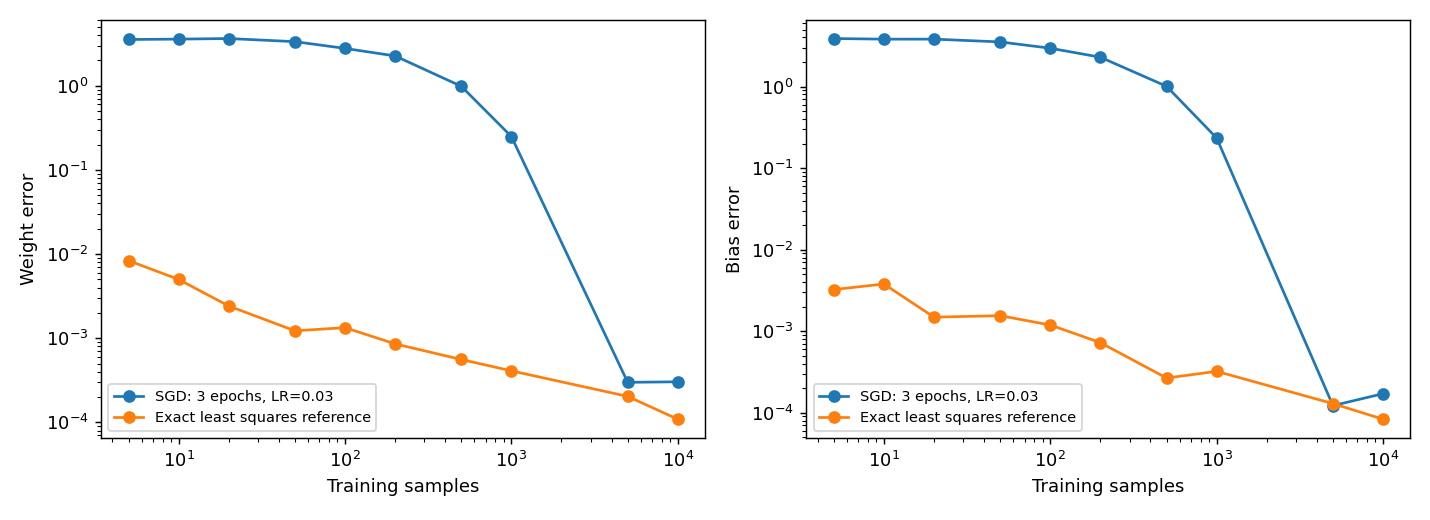

In [6]:
result = run_section("3.5", recompute=RECOMPUTE)
render_result(result)

## 3.6 — Generalization (7 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 157 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. When can you solve the problem of polynomial regression exactly?
118 Linear Neural Networks for Regression
83
2. Giveatleastfiveexampleswheredependentrandomvariablesmaketreatingtheproblem
as IID data inadvisable.
3. Can you ever expect to see zero training error? Under which circumstances would you
see zero generalization error?
4. Why is𝐾-fold cross-validation very expensive to compute?
5. Why is the𝐾-fold cross-validation error estimate biased?
6. The VC dimension is defined as the maximum number of points that can be classified
with arbitrary labels{±1} by a function of a class of functions. Why might this not be
a good idea for measuring how complex the class of functions is? Hint: consider the
magnitude of the functions.
7. Your manager gives you a difficult dataset on which your current algorithm does not
perform so well. How would you justify to him that you need more data? Hint: you
cannot increase the data but you can decrease it.
</pre>
</details>


### Câu 1

Hồi quy đa thức bậc d giải bình phương tối thiểu bằng ma trận Vandermonde.
Nếu n=d+1 điểm x phân biệt thì có đa thức nội suy duy nhất; n≤d+1 có thể
nội suy nhưng chưa chắc duy nhất. Khi n>d+1 chỉ khớp chính xác nếu nhãn nằm trong
không gian cột; thiếu hạng dùng pseudoinverse. Khớp train chính xác không bảo đảm tổng quát hóa.

### Câu 2

Năm ví dụ không nên chia ngẫu nhiên như IID: chuỗi thời gian liền kề; ảnh nhiều
khung của cùng video; nhiều lần đo một bệnh nhân; văn bản của cùng tác giả/tài liệu;
đo đạc địa lý gần nhau. Dùng time split, group split hoặc spatial split tương ứng.

### Câu 3

Có thể zero train error khi mô hình nội suy/ghi nhớ, hoặc dữ liệu không nhiễu và
mô hình đúng. Zero generalization error đòi hỏi nhiệm vụ xác định và hàm học đúng
trên phân phối đánh giá; nhiễu không loại bỏ tạo ra Bayes error dương. Với classification,
zero 0–1 error khác với cross-entropy đúng bằng 0.

### Câu 4

K-fold huấn luyện K mô hình cho mỗi cấu hình; H cấu hình cần khoảng K·H lần fit.
Tiền xử lý cũng phải fit riêng từng fold. Đó là chi phí lớn khi mạng sâu học lâu.

### Câu 5

CV đánh giá mô hình học trên (K−1)/K dữ liệu, không phải mô hình cuối học toàn bộ;
cỡ train nhỏ hơn thường gây thiên lệch bi quan, nhưng dấu bias không tuyệt đối trong
mọi thuật toán. Thử nhiều cấu hình và chọn min CV còn có selection bias lạc quan.

### Câu 6

VC dimension đếm khả năng shatter nhãn, bỏ qua norm, margin, độ trơn và thuật toán
chọn nghiệm. Hai lớp cùng VC dimension có thể có mức tổng quát hóa thực tế khác;
với hồi quy thực liên tục còn cần các khái niệm như pseudo-dimension/Rademacher complexity.

### Câu 7

Giảm tập train thành các kích thước khác nhau, giữ validation cố định và vẽ learning
curve. Nếu val error còn giảm theo n trong khi train/val có khoảng cách, đó là bằng
chứng thêm dữ liệu có thể giúp. Nếu cả hai lỗi cao và phẳng, cần cải thiện mô hình/
đặc trưng/tối ưu, chưa thể chỉ yêu cầu thêm dữ liệu. Notebook thực hiện đường học này.

**learning_curve**

,n,train_mse,validation_mse
0,5,0.020719,0.327282
1,10,0.091991,0.294855
2,20,0.134089,0.265880
3,50,0.167793,0.267184
4,100,0.187460,0.274405
5,200,0.231668,0.265642
6,500,0.233009,0.262312
7,1000,0.249522,0.260194


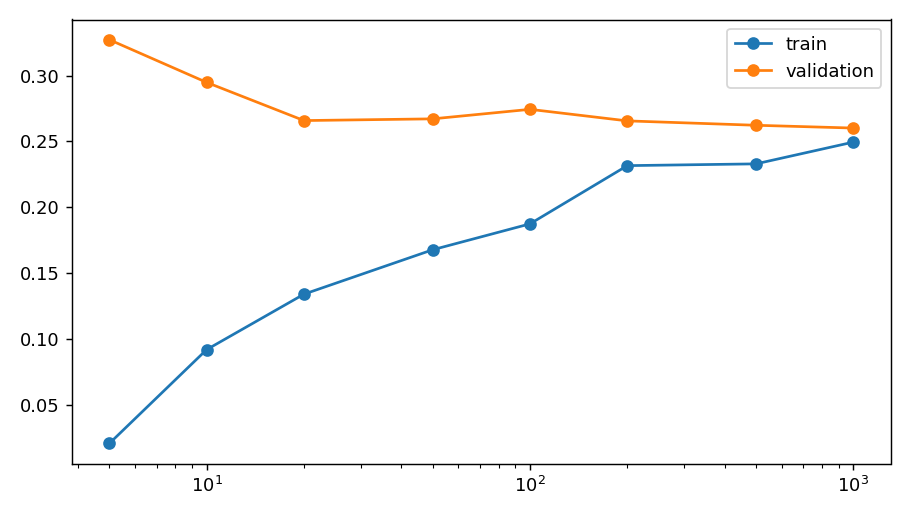

In [7]:
result = run_section("3.6", recompute=RECOMPUTE)
render_result(result)

## 3.7 — Weight Decay (6 câu)

<details><summary>Đối chiếu đề gốc — PDF trang 164 (bấm để mở)</summary>

Bản trích text có thể mất vị trí chỉ số/số mũ; xem PDF gốc để đọc công thức chính xác.

<pre>Exercises
1. Experiment with the value of𝜆 in the estimation problem in this section. Plot training
and validation accuracy as a function of𝜆. What do you observe?
2. Use a validation set to find the optimal value of𝜆. Is it really the optimal value? Does
this matter?
3. What would the update equations look like if instead of‖w‖2 we used˝𝑖|𝑤𝑖| as our
penalty of choice (ℓ1 regularization)?
4. We know that‖w‖2 = w⊤w. Can you find a similar equation for matrices (see the
Frobenius norm inSection 2.3.11)?
5. Review the relationship between training error and generalization error. In addition to
weight decay, increased training, and the use of a model of suitable complexity, what
other ways might help us deal with overfitting?
6. In Bayesian statistics we use the product of prior and likelihood to arrive at a posterior
via𝑃(𝑤|𝑥)∝ 𝑃(𝑥|𝑤)𝑃(𝑤). How can you identify𝑃(𝑤) with regularization?
</pre>
</details>


### Câu 1

Đề viết “accuracy” trong bài hồi quy; ở đây báo cáo train/validation **MSE** cho
đúng đại lượng. Dữ liệu đúng mục 3.7: y=0.05+Σ0.01xᵢ+ε, std(ε)=0.01,
20 train/100 validation, d=200. Đường chính dùng SGD, **batch5, LR=0.01,
10 epoch**, khảo sát λ=0/0.01/0.1/1/3/10; không phạt bias.
Ridge quá yếu có thể overfit, quá mạnh có thể underfit. Bảng ridge giải chính xác
ở lưới 0…100 chỉ là tham chiếu riêng, không thay cho kết quả SGD của mục này.

### Câu 2

Chọn λ có validation MSE thấp nhất trong lưới đã thử. Đó không bảo đảm tối ưu
trên mọi λ hoặc dữ liệu mới vì validation hữu hạn và đã dùng chọn mô hình.
Giá trị đủ tốt/ổn định thường quan trọng hơn λ chính xác tuyệt đối; cần test độc lập
hoặc nested CV nếu cần ước lượng tổng quát hóa sau chọn tham số.

### Câu 3

Nếu giữ hệ số λ/2 như biểu thức sách và thay bình phương norm bằng Σ|wᵢ|,
J=L+(λ/2)Σ|wᵢ|: cập nhật `w←w−η(∇L+(λ/2)sign(w))`, chọn
subgradient trong [−1,1] tại 0. Proximal gradient cho nghiệm thưa rõ hơn:
`w←sign(z) max(|z|−ηλ/2,0)`, z=w−η∇L. Nếu định nghĩa lại J=L+λΣ|wᵢ|,
hệ số trong gradient và ngưỡng là λ thay vì λ/2. Bias có thể không phạt.

### Câu 4

‖W‖²_F=ΣᵢⱼWᵢⱼ²=tr(WᵀW)=tr(WWᵀ), tương tự wᵀw cho vector.

### Câu 5

Có thể thêm dữ liệu phù hợp, augmentation bảo toàn nhãn, early stopping, dropout,
giảm leakage và chọn đặc trưng. Tăng thời gian train tự nó không phải thuốc chống
overfit; phải theo dõi validation. Những biện pháp có thể không cộng hiệu quả tuyến tính.

### Câu 6

MAP cực đại log likelihood + log prior, tương đương NLL − log prior.
Prior Gaussian mean 0 tạo L2; Laplace tạo L1. Hệ số λ phụ thuộc variance prior,
quy ước tổng/trung bình loss và cỡ mẫu; không đồng nhất mọi optimizer weight decay
với cùng một MAP (AdamW tách decay là trường hợp cần phân biệt).

Regression has no classification accuracy: report unpenalized MSE. Main curve is SGD, LR=.01, batch=5, 10 epochs, true bias=.05, no bias penalty. Exact ridge is a separate reference, not the SGD result.


**weight_decay**

,lambda,train_mse,validation_mse,weight_norm
0,0.00,0.000020,0.032820,0.130827
1,0.01,0.000020,0.032698,0.130355
2,0.10,0.000023,0.031645,0.126192
3,1.00,0.000164,0.024941,0.092174
4,3.00,0.000948,0.021553,0.051297
5,10.00,0.004921,0.022568,0.024209


**exact_ridge_reference**

,lambda,train_mse,validation_mse,weight_norm
0,0.00000,2.876617e-32,0.023724,0.045982
1,0.00001,2.141250e-14,0.020628,0.045193
2,0.00010,2.141206e-12,0.020628,0.045193
3,0.00100,2.140767e-10,0.020628,0.045189
4,0.01000,2.136388e-08,0.020625,0.045146
5,0.10000,2.093407e-06,0.020599,0.044725
6,1.00000,1.731888e-04,0.020387,0.040949
7,10.00000,5.041692e-03,0.019860,0.022581
8,100.00000,1.687786e-02,0.020158,0.004186


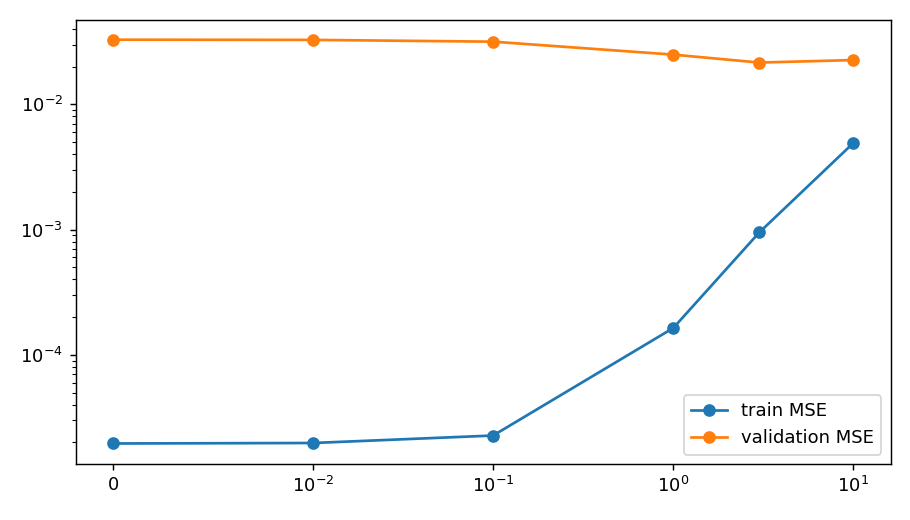

In [8]:
result = run_section("3.7", recompute=RECOMPUTE)
render_result(result)

**Kết quả SGD đúng dữ liệu mục 3.7:** bias thật 0.05, 20 train/100 validation, batch5, LR=0.01, 10 epoch. λ=3 có validation MSE thấp nhất lưới (0.021553); λ=0 cho 0.032820. Bảng exact ridge là tham chiếu riêng.